#  bibliothèque & chargement de données

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

df = pd.read_csv('TrainRides.csv' , sep=";")

# exploration des données

In [68]:
df.head(10)

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request
0,da8a6ba8-b3dc-4677-b176,08/12/2023,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,01/01/2024,11:00:00,13:30:00,13:30:00,On Time,NaN,No
1,b0cdd1b0-f214-4197-be53,16/12/2023,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,01/01/2024,09:45:00,11:35:00,11:40:00,Delayed,Signal Failure,No
2,f3ba7a96-f713-40d9-9629,19/12/2023,19:51:27,Online,Credit Card,NaN,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,02/01/2024,18:15:00,18:45:00,18:45:00,On Time,NaN,No
3,b2471f11-4fe7-4c87-8ab4,20/12/2023,23:00:36,Station,Credit Card,NaN,Standard,Advance,13,London Paddington,Reading,01/01/2024,21:30:00,22:30:00,22:30:00,On Time,NaN,No
4,2be00b45-0762-485e-a7a3,27/12/2023,18:22:56,Online,Contactless,NaN,Standard,Advance,76,Liverpool Lime Street,London Euston,01/01/2024,16:45:00,19:00:00,19:00:00,On Time,NaN,No
5,4e1dcd88-3d95-44ef-99fa,30/12/2023,07:56:06,Online,Credit Card,NaN,Standard,Advance,35,London Kings Cross,York,01/01/2024,06:15:00,08:05:00,08:05:00,On Time,NaN,No
6,1c74479d-85a4-4ba1-a607,31/12/2023,00:02:01,Station,Credit Card,Adult,Standard,Advance,2,London Euston,Oxford,01/01/2024,22:30:00,23:40:00,23:40:00,On Time,NaN,No
7,febf8dab-f808-46fa-bf2b,31/12/2023,01:35:18,Station,Contactless,Disabled,Standard,Advance,2,Liverpool Lime Street,Manchester Piccadilly,01/01/2024,00:00:00,00:30:00,00:30:00,On Time,NaN,No
8,01df916f-4291-41ec-a37d,31/12/2023,01:43:09,Station,Credit Card,NaN,Standard,Advance,37,London Euston,York,01/01/2024,00:00:00,01:50:00,02:07:00,Delayed,Signal Failure,No
9,a8cedba7-1923-459d-b046,31/12/2023,03:05:52,Online,Credit Card,NaN,Standard,Advance,13,London Paddington,Reading,01/01/2024,01:30:00,02:30:00,02:30:00,On Time,NaN,No


In [69]:
df.columns

Index(['Transaction ID', 'Date of Purchase', 'Time of Purchase',
       'Purchase Type', 'Payment Method', 'Railcard', 'Ticket Class',
       'Ticket Type', 'Price', 'Departure Station', 'Arrival Destination',
       'Date of Journey', 'Departure Time', 'Arrival Time',
       'Actual Arrival Time', 'Journey Status', 'Reason for Delay',
       'Refund Request'],
      dtype='object')

In [70]:
df.shape

(31653, 18)

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31653 entries, 0 to 31652
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Transaction ID       31653 non-null  object
 1   Date of Purchase     31653 non-null  object
 2   Time of Purchase     31653 non-null  object
 3   Purchase Type        31653 non-null  object
 4   Payment Method       31653 non-null  object
 5   Railcard             10735 non-null  object
 6   Ticket Class         31653 non-null  object
 7   Ticket Type          31653 non-null  object
 8   Price                31653 non-null  int64 
 9   Departure Station    31653 non-null  object
 10  Arrival Destination  31653 non-null  object
 11  Date of Journey      31653 non-null  object
 12  Departure Time       31653 non-null  object
 13  Arrival Time         31653 non-null  object
 14  Actual Arrival Time  29773 non-null  object
 15  Journey Status       31653 non-null  object
 16  Reas

In [72]:
df.describe()

,Price
count,31653.000000
mean,23.439200
std,29.997628
min,1.000000
25%,5.000000
50%,11.000000
75%,35.000000
max,267.000000


In [73]:
df.nunique()

,0
Transaction ID,31653
Date of Purchase,128
Time of Purchase,24351
Purchase Type,2
Payment Method,3
Railcard,3
Ticket Class,2
Ticket Type,3
Price,125
Departure Station,12


In [74]:
df['Price'].describe()

,Price
count,31653.000000
mean,23.439200
std,29.997628
min,1.000000
25%,5.000000
50%,11.000000
75%,35.000000
max,267.000000


In [75]:
df.query("Price < 0",) ["Price"].head(4)

,Price


# typages

In [76]:

# Conversion des dates
df['Date of Purchase'] = pd.to_datetime(df['Date of Purchase'], format='%d/%m/%Y', errors='coerce')
df['Date of Journey'] = pd.to_datetime(df['Date of Journey'], format='%d/%m/%Y', errors='coerce')

# Conversion des catégories
cat_cols = ['Purchase Type', 'Payment Method', 'Railcard', 'Ticket Class','Reason for Delay', 'Ticket Type', 'Journey Status', 'Refund Request']
for col in cat_cols:
    df[col] = df[col].astype('category')

# Conversion du prix
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

# Conversion heure
df['Time of Purchase'] = pd.to_timedelta(df['Time of Purchase'], errors='coerce')
df['Actual Arrival Time'] = pd.to_timedelta(df['Actual Arrival Time'], errors='coerce')
df['Departure Time'] = pd.to_timedelta(df['Departure Time'], errors='coerce')
df['Arrival Time'] = pd.to_timedelta(df['Arrival Time'], errors='coerce')


df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31653 entries, 0 to 31652
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype          
---  ------               --------------  -----          
 0   Transaction ID       31653 non-null  object         
 1   Date of Purchase     31653 non-null  datetime64[ns] 
 2   Time of Purchase     31653 non-null  timedelta64[ns]
 3   Purchase Type        31653 non-null  category       
 4   Payment Method       31653 non-null  category       
 5   Railcard             10735 non-null  category       
 6   Ticket Class         31653 non-null  category       
 7   Ticket Type          31653 non-null  category       
 8   Price                31653 non-null  int64          
 9   Departure Station    31653 non-null  object         
 10  Arrival Destination  31653 non-null  object         
 11  Date of Journey      31653 non-null  datetime64[ns] 
 12  Departure Time       31653 non-null  timedelta64[ns]
 13  Arrival Time    

# doublons

In [77]:
print(f"doublons : { df.duplicated().sum()}")
display(df[df.duplicated(keep=False)])

doublons : 0


,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request


In [78]:
duplicated_ids= df[df.duplicated(subset=['Transaction ID'], keep=False)]
print(f"nombre de ligne avec id identique : {len(duplicated_ids)}")

nombre de ligne avec id identique : 0


# valeurs manquantes

In [79]:
df.isnull().sum()

,0
Transaction ID,0
Date of Purchase,0
Time of Purchase,0
Purchase Type,0
Payment Method,0
Railcard,20918
Ticket Class,0
Ticket Type,0
Price,0
Departure Station,0


In [80]:
#1. Traitement de 'Reason for Delay'
if 'Reason for Delay' in df.columns:
    # S'assurer que 'Reason for Delay' est de type catégorie pour y ajouter 'No Delay'
    if not isinstance(df['Reason for Delay'].dtype, pd.CategoricalDtype):
        df['Reason for Delay'] = df['Reason for Delay'].astype('category')
    if 'No Delay' not in df['Reason for Delay'].cat.categories:
        df['Reason for Delay'] = df['Reason for Delay'].cat.add_categories(['No Delay'])
    df['Reason for Delay'] = df['Reason for Delay'].fillna('No Delay')

# 2. Traitement de 'Railcard'
if 'Railcard' in df.columns:
    if not isinstance(df['Railcard'].dtype, pd.CategoricalDtype):
        df['Railcard'] = df['Railcard'].astype('category')
    if 'None' not in df['Railcard'].cat.categories:
        df['Railcard'] = df['Railcard'].cat.add_categories(['None'])
    df['Railcard'] = df['Railcard'].fillna('None')

# 3. Traitement de 'Actual Arrival Time'
if 'Actual Arrival Time' in df.columns and 'Arrival Time' in df.columns:
    df['Actual Arrival Time'] = df['Actual Arrival Time'].fillna(df['Arrival Time'])

# Vérification du nombre de valeurs manquantes restantes
print("Nombre de valeurs manquantes après traitement :")


display(df.isnull().sum())

Nombre de valeurs manquantes après traitement :


,0
Transaction ID,0
Date of Purchase,0
Time of Purchase,0
Purchase Type,0
Payment Method,0
Railcard,0
Ticket Class,0
Ticket Type,0
Price,0
Departure Station,0


# valeurs aberrantes

In [81]:
def traiter_aberrants(col):
    Q1 = col.quantile(0.25)
    Q3 = col.quantile(0.75)
    IQR = Q3 - Q1
    inf = Q1 - 1.5*IQR
    sup = Q3 + 1.5*IQR
    return col.clip(inf, sup)

# Tu l'appliques seulement aux colonnes numériques
num_cols = ['Price']
for Price in num_cols:
    df["Price"] = traiter_aberrants(df["Price"])

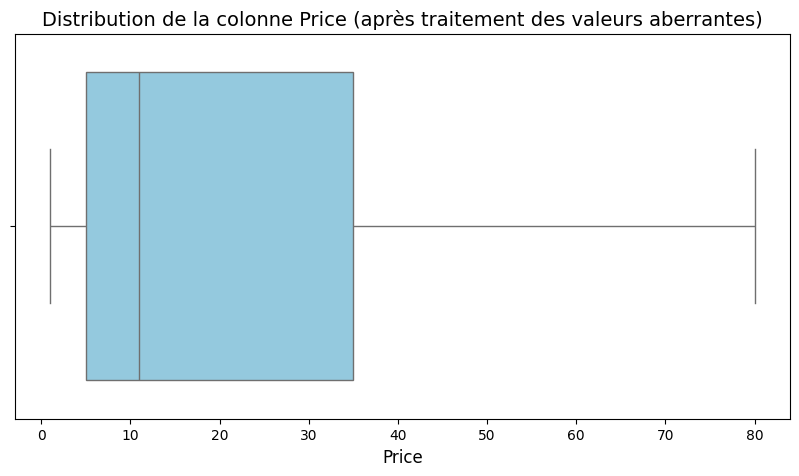

In [82]:
# Configuration de la figure
plt.figure(figsize=(10, 5))

# Création du boxplot pour la colonne 'Price'
sb.boxplot(x=df['Price'], color='skyblue')

# Ajout des labels et du titre
plt.title('Distribution de la colonne Price (après traitement des valeurs aberrantes)', fontsize=14)
plt.xlabel('Price', fontsize=12)

# Affichage du graphique
plt.show()

# harmoniser

In [84]:
display(df["Reason for Delay"].nunique())
display(df["Reason for Delay"].value_counts())

9

,count
Reason for Delay,
No Delay,27481
Weather,995
Technical Issue,707
Signal Failure,523
Signal failure,447
Staffing,410
Staff Shortage,399
Weather Conditions,377
Traffic,314


In [85]:
# Réappliquer les conversions nécessaires pour cette colonne
df["Reason for Delay"] = df["Reason for Delay"].astype(str)

harmonisation = {
    "Weather": "Weather Conditions",
    "Staffing": "Staff Shortage",
    "Signal failure": "Signal Failure"
}

df["Reason for Delay"] = df["Reason for Delay"].replace(harmonisation)

# Convertir à nouveau en catégorie en excluant les valeurs 'nan' (issues de float NaN convertis en str)
df["Reason for Delay"] = df["Reason for Delay"].replace('nan', np.nan).astype('category')

print("Nombre de catégories uniques après harmonisation :", df["Reason for Delay"].nunique())
display(df["Reason for Delay"].value_counts())

Nombre de catégories uniques après harmonisation : 6


,count
Reason for Delay,
No Delay,27481
Weather Conditions,1372
Signal Failure,970
Staff Shortage,809
Technical Issue,707
Traffic,314


# nouvelle colonnes

In [86]:
df["trajet"] = df["Departure Time"] - (- df['Actual Arrival Time'])

# version finie

In [89]:
df.head(20)

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,trajet
0,da8a6ba8-b3dc-4677-b176,2023-12-08,0 days 12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,2024-01-01,0 days 11:00:00,0 days 13:30:00,0 days 13:30:00,On Time,No Delay,No,1 days 00:30:00
1,b0cdd1b0-f214-4197-be53,2023-12-16,0 days 11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,2024-01-01,0 days 09:45:00,0 days 11:35:00,0 days 11:40:00,Delayed,Signal Failure,No,0 days 21:25:00
2,f3ba7a96-f713-40d9-9629,2023-12-19,0 days 19:51:27,Online,Credit Card,None,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,2024-01-02,0 days 18:15:00,0 days 18:45:00,0 days 18:45:00,On Time,No Delay,No,1 days 13:00:00
3,b2471f11-4fe7-4c87-8ab4,2023-12-20,0 days 23:00:36,Station,Credit Card,None,Standard,Advance,13,London Paddington,Reading,2024-01-01,0 days 21:30:00,0 days 22:30:00,0 days 22:30:00,On Time,No Delay,No,1 days 20:00:00
4,2be00b45-0762-485e-a7a3,2023-12-27,0 days 18:22:56,Online,Contactless,None,Standard,Advance,76,Liverpool Lime Street,London Euston,2024-01-01,0 days 16:45:00,0 days 19:00:00,0 days 19:00:00,On Time,No Delay,No,1 days 11:45:00
5,4e1dcd88-3d95-44ef-99fa,2023-12-30,0 days 07:56:06,Online,Credit Card,None,Standard,Advance,35,London Kings Cross,York,2024-01-01,0 days 06:15:00,0 days 08:05:00,0 days 08:05:00,On Time,No Delay,No,0 days 14:20:00
6,1c74479d-85a4-4ba1-a607,2023-12-31,0 days 00:02:01,Station,Credit Card,Adult,Standard,Advance,2,London Euston,Oxford,2024-01-01,0 days 22:30:00,0 days 23:40:00,0 days 23:40:00,On Time,No Delay,No,1 days 22:10:00
7,febf8dab-f808-46fa-bf2b,2023-12-31,0 days 01:35:18,Station,Contactless,Disabled,Standard,Advance,2,Liverpool Lime Street,Manchester Piccadilly,2024-01-01,0 days 00:00:00,0 days 00:30:00,0 days 00:30:00,On Time,No Delay,No,0 days 00:30:00
8,01df916f-4291-41ec-a37d,2023-12-31,0 days 01:43:09,Station,Credit Card,None,Standard,Advance,37,London Euston,York,2024-01-01,0 days 00:00:00,0 days 01:50:00,0 days 02:07:00,Delayed,Signal Failure,No,0 days 02:07:00
9,a8cedba7-1923-459d-b046,2023-12-31,0 days 03:05:52,Online,Credit Card,None,Standard,Advance,13,London Paddington,Reading,2024-01-01,0 days 01:30:00,0 days 02:30:00,0 days 02:30:00,On Time,No Delay,No,0 days 04:00:00


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31653 entries, 0 to 31652
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype          
---  ------               --------------  -----          
 0   Transaction ID       31653 non-null  object         
 1   Date of Purchase     31653 non-null  datetime64[ns] 
 2   Time of Purchase     31653 non-null  timedelta64[ns]
 3   Purchase Type        31653 non-null  category       
 4   Payment Method       31653 non-null  category       
 5   Railcard             31653 non-null  category       
 6   Ticket Class         31653 non-null  category       
 7   Ticket Type          31653 non-null  category       
 8   Price                31653 non-null  int64          
 9   Departure Station    31653 non-null  object         
 10  Arrival Destination  31653 non-null  object         
 11  Date of Journey      31653 non-null  datetime64[ns] 
 12  Departure Time       31653 non-null  timedelta64[ns]
 13  Arrival Time    

In [92]:
df.isnull().sum()

,0
Transaction ID,0
Date of Purchase,0
Time of Purchase,0
Purchase Type,0
Payment Method,0
Railcard,0
Ticket Class,0
Ticket Type,0
Price,0
Departure Station,0


In [93]:
df.to_csv('TrainRides_clean.csv', index=False, sep=';')